# Machine Learning – Assignment 2
### Multiclass classification of dry beans · M.Tech (AIML)

**Goal.** Train and compare five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) on the
*same* dataset and the *same* stratified 80:20 split, using six metrics: Accuracy, AUC, Precision, Recall, F1 and MCC.

**Dataset.** UCI *Dry Bean* – 13,611 instances, 16 numeric features, target `Class` (7 bean varieties). License: CC BY 4.0.
- UCI: https://archive.ics.uci.edu/dataset/602/dry+bean+dataset  (DOI https://doi.org/10.24432/C50S4B)
- Kaggle: https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset
- Authors' page: https://www.muratkoklu.com/datasets/
- Citation: KOKLU, M. and OZKAN, I.A., (2020), Multiclass Classification of Dry Beans Using Computer Vision and Machine Learning Techniques. Computers and Electronics in Agriculture, 174, 105507. DOI: https://doi.org/10.1016/j.compag.2020.105507

**Notebook map** – Phase 1 data loading → 2 validation & EDA → 3 preprocessing → 4 training → 5 metrics → 6 comparison → 7 saving models.
All reusable logic lives in `src/`; this notebook calls it and explains each step, so the notebook, the CLI scripts and the Streamlit app always agree.

In [1]:
import sys, os, json, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# Make the project root importable whether the notebook is opened from notebooks/ or from the root.
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display, Markdown

import config
from src import data_loader, preprocessing, train_models, evaluate_models as ev, visualization as viz
%matplotlib inline
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("Project root:", ROOT)

Project root: /home/claude/ML_Assignment_2


## Phase 1 · Dataset selection and loading

**Concept.** A reproducible project needs a scripted way to obtain the data. Two independent sources are provided below;
**exactly one** should be active. Both are routed through `standardize_columns()` so every later cell sees identical column names
(the original Excel file spells two columns `AspectRation` and `roundness`, the UCI listing uses `AspectRatio` and `Roundness`;
only the *names* are harmonised – values are never touched).

**How to switch source:** comment out the active option and un-comment the other. Nothing else in the notebook changes.

> In this delivered notebook **Option B is active** because it was executed in an environment without access to the UCI server.
> On your machine (with internet) you can make Option A the active one – see the troubleshooting list at the end if it fails.

In [2]:
# ============================================================================
# OPTION A: UCI  (ucimlrepo, needs internet)
# ----------------------------------------------------------------------------
# To use: un-comment the next line AND comment out Option B below.
# df_raw = data_loader.load_from_uci()          # fetch_ucirepo(id=602) -> features + targets -> one DataFrame
# ============================================================================

# ============================================================================
# OPTION B: KAGGLE / author download (Excel or CSV in data/raw/)
# ----------------------------------------------------------------------------
# 1. Download from Kaggle (https://www.kaggle.com/datasets/muratkokludataset/dry-bean-dataset)
#    or the authors' page, and put the file in data/raw/ (the .xlsx is already bundled).
# 2. Choose the file and the name of the target column below.
SOURCE_FILE = config.RAW_EXCEL        # e.g. config.RAW_DIR / "Dry_Bean_Dataset.csv" also works
TARGET_COLUMN = "Class"               # change only if your file names the target differently
df_raw = data_loader.load_from_file(SOURCE_FILE, target_col=TARGET_COLUMN)
# ============================================================================

data_loader.save_raw_csv(df_raw)      # keep a CSV copy in data/raw/ (identical values, standardised names)
print("Loaded:", df_raw.shape, "| columns:", list(df_raw.columns)[:4], "...")

Loaded: (13611, 17) | columns: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength'] ...


### Validation: does the dataset satisfy the assignment, and do both sources give the same schema?
`validate_dataset` raises an error if any of the 16 features or the target is missing or an unexpected column exists.
We then *simulate* the other source's column spelling and confirm both map to the same schema
(this checks the renaming logic; it is not a download from the other source).

In [3]:
report = data_loader.validate_dataset(df_raw)
print(f"Dimensions        : {report['shape'][0]} rows x {report['shape'][1]} columns")
print(f"Input features    : {report['n_features']}  (assignment minimum 12 -> {'OK' if report['n_features'] >= 12 else 'FAIL'})")
print(f"Instances         : {report['shape'][0]}  (assignment minimum 500 -> {'OK' if report['shape'][0] >= 500 else 'FAIL'})")
print(f"Target column     : {report['target']}  ({report['n_classes']} classes)")
print(f"Missing values    : {report['missing_values']}")
print(f"Duplicate records : {report['duplicate_rows']}")
print("Class distribution:", report['class_distribution'])
print()
print(df_raw.dtypes.to_string())

# Same-schema check using both naming styles (simulated)
excel_style = df_raw.rename(columns={"AspectRatio": "AspectRation", "Roundness": "roundness"})
uci_style = df_raw.rename(columns={"AspectRatio": "AspectRatio", "Roundness": "Roundness"})
assert data_loader.schemas_match(excel_style, uci_style)
assert data_loader.standardize_columns(excel_style).equals(data_loader.standardize_columns(uci_style))
print("\nSchema check passed: both naming styles standardise to identical columns and values.")

Dimensions        : 13611 rows x 17 columns
Input features    : 16  (assignment minimum 12 -> OK)
Instances         : 13611  (assignment minimum 500 -> OK)
Target column     : Class  (7 classes)
Missing values    : 0
Duplicate records : 68
Class distribution: {'DERMASON': 3546, 'SIRA': 2636, 'SEKER': 2027, 'HOROZ': 1928, 'CALI': 1630, 'BARBUNYA': 1322, 'BOMBAY': 522}

Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class                  str

Schema check passed: both naming styles standardise to identical columns and values.


## Phase 2 · Exploratory Data Analysis (EDA)
**Why EDA?** Before modelling we must know the data's size, types, quality problems (missing values, duplicates, outliers),
class balance and feature relationships – these drive the preprocessing and the choice of metrics.
Figures are saved to `reports/figures/`.

In [4]:
print('First 5 records'); display(df_raw.head())
print('Last 5 records'); display(df_raw.tail())

First 5 records


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


Last 5 records


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
13606,42097,759.696,288.721612,185.944705,1.552728,0.765002,42508,231.515799,0.714574,0.990331,0.916603,0.801865,0.006858,0.001749,0.642988,0.998385,DERMASON
13607,42101,757.499,281.576392,190.713136,1.476439,0.735702,42494,231.526798,0.799943,0.990752,0.922015,0.822252,0.006688,0.001886,0.676099,0.998219,DERMASON
13608,42139,759.321,281.539928,191.187979,1.472582,0.734065,42569,231.631261,0.729932,0.989899,0.918424,0.822730,0.006681,0.001888,0.676884,0.996767,DERMASON
13609,42147,763.779,283.382636,190.275731,1.489326,0.741055,42667,231.653248,0.705389,0.987813,0.907906,0.817457,0.006724,0.001852,0.668237,0.995222,DERMASON
13610,42159,772.237,295.142741,182.204716,1.619841,0.786693,42600,231.686223,0.788962,0.989648,0.888380,0.784997,0.007001,0.001640,0.616221,0.998180,DERMASON


In [5]:
print("Shape:", df_raw.shape)
print("\nColumn names:", list(df_raw.columns))
print("\nData types and non-null counts:")
df_raw.info()
cat_cols = df_raw.drop(columns=[config.TARGET_COL]).select_dtypes(include=["object", "string", "category"]).columns.tolist()
num_cols = df_raw.drop(columns=[config.TARGET_COL]).select_dtypes(include="number").columns.tolist()
print(f"\nCategorical predictors: {cat_cols or 'none'}   |   Numerical predictors: {len(num_cols)}")
print("-> every predictor is numeric, so no encoder is needed for X; only the target is label-encoded.")

Shape: (13611, 17)

Column names: ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data types and non-null counts:
<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRatio      13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  Roundness        13611 non-null  

**Statistical summary** – look at the very different scales (e.g. `Area` ~ 10⁴–10⁵ vs `Solidity` ≈ 0.9). Distance- and gradient-based models need scaling; this is why a `StandardScaler` is part of every pipeline.

In [6]:
display(df_raw.describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.2845,29324.0957,20420.0000,36328.0000,44652.0000,61332.0000,254616.0000
Perimeter,13611.0,855.2835,214.2897,524.7360,703.5235,794.9410,977.2130,1985.3700
MajorAxisLength,13611.0,320.1419,85.6942,183.6012,253.3036,296.8834,376.4950,738.8602
MinorAxisLength,13611.0,202.2707,44.9701,122.5127,175.8482,192.4317,217.0317,460.1985
AspectRatio,13611.0,1.5832,0.2467,1.0249,1.4323,1.5511,1.7071,2.4303
Eccentricity,13611.0,0.7509,0.0920,0.2190,0.7159,0.7644,0.8105,0.9114
ConvexArea,13611.0,53768.2002,29774.9158,20684.0000,36714.5000,45178.0000,62294.0000,263261.0000
EquivDiameter,13611.0,253.0642,59.1771,161.2438,215.0680,238.4380,279.4465,569.3744
Extent,13611.0,0.7497,0.0491,0.5553,0.7186,0.7599,0.7869,0.8662
Solidity,13611.0,0.9871,0.0047,0.9192,0.9857,0.9883,0.9900,0.9947


**Missing values and duplicates.** Missing values would need imputation or row removal; exact duplicate rows would let the *same* bean appear in both the train and test sets and inflate scores.

In [7]:
missing = df_raw.isna().sum()
print("Missing values per column (non-zero only):", missing[missing > 0].to_dict() or "none")
dups = df_raw.duplicated()
print("Duplicate rows:", int(dups.sum()), f"({dups.mean():.2%})")
display(df_raw[df_raw.duplicated(keep=False)].sort_values(list(df_raw.columns)).head(6))

Missing values per column (non-zero only): none
Duplicate rows: 68 (0.50%)


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
5504,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5505,33518,702.956,277.571399,154.305581,1.798842,0.831240,34023,206.582775,0.808383,0.985157,0.852377,0.744251,0.008281,0.001567,0.553909,0.996396,HOROZ
5508,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5509,33954,716.750,277.368480,156.356326,1.773951,0.825970,34420,207.922042,0.799482,0.986461,0.830549,0.749624,0.008169,0.001591,0.561936,0.996847,HOROZ
5547,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ
5548,38427,756.323,306.533886,160.591784,1.908777,0.851782,38773,221.193978,0.796976,0.991076,0.844174,0.721597,0.007977,0.001334,0.520702,0.993905,HOROZ


**Target class distribution and imbalance.** If a class is rare, accuracy alone can hide poor performance on it – hence macro-averaged metrics and MCC.

,count,share
Class,,
DERMASON,3546,0.2605
SIRA,2636,0.1937
SEKER,2027,0.1489
HOROZ,1928,0.1417
CALI,1630,0.1198
BARBUNYA,1322,0.0971
BOMBAY,522,0.0384


Imbalance ratio (largest / smallest class): 6.79


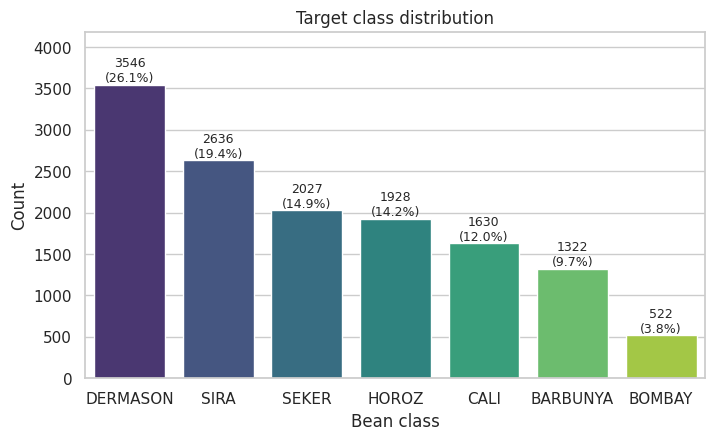

In [8]:
counts = df_raw[config.TARGET_COL].value_counts()
display(counts.to_frame("count").assign(share=(counts / counts.sum()).round(4)))
print(f"Imbalance ratio (largest / smallest class): {counts.max() / counts.min():.2f}")
fig = viz.plot_class_distribution(df_raw); viz.save_fig(fig, "class_distribution.png"); plt.show()

**Feature distributions** – check skewness and ranges.

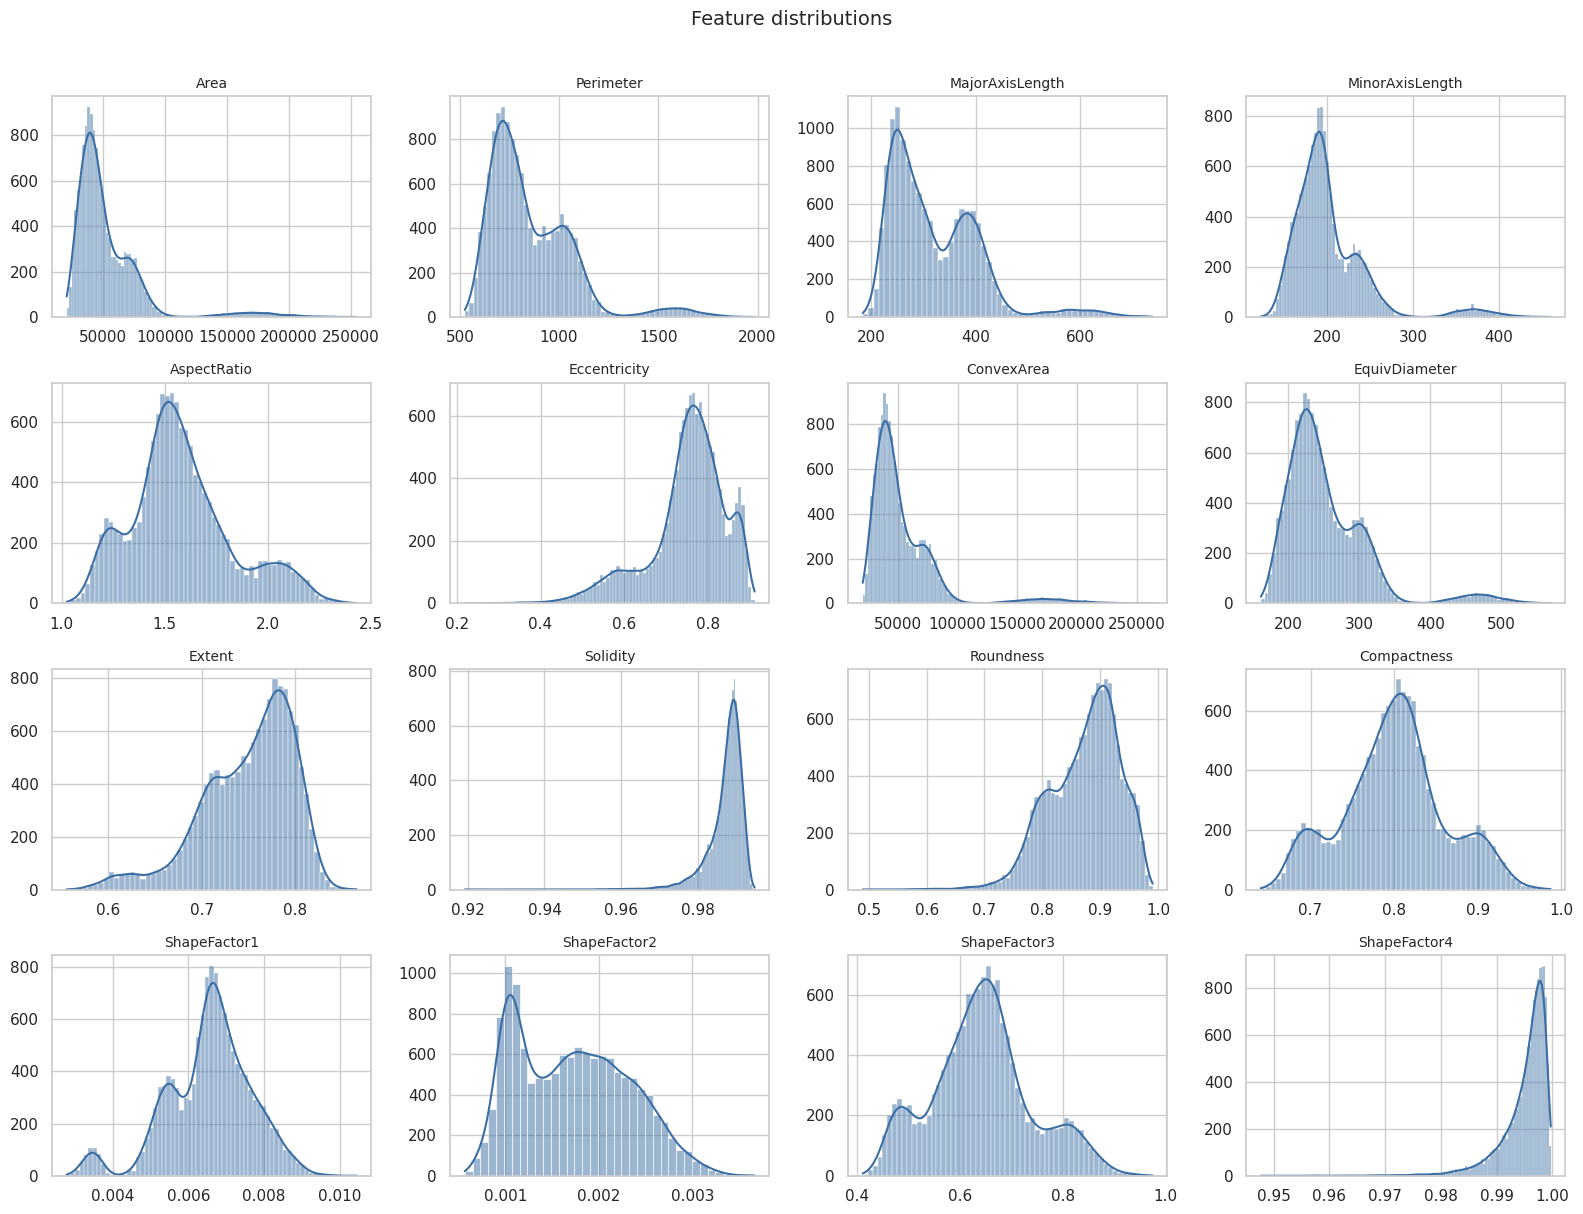

In [9]:
fig = viz.plot_feature_distributions(df_raw); viz.save_fig(fig, 'feature_distributions.png'); plt.show()

**Boxplots** – outliers show up as points beyond the whiskers. We do **not** delete them: they are genuine measurements and we must not alter data silently; scaling + robust models cope with them.

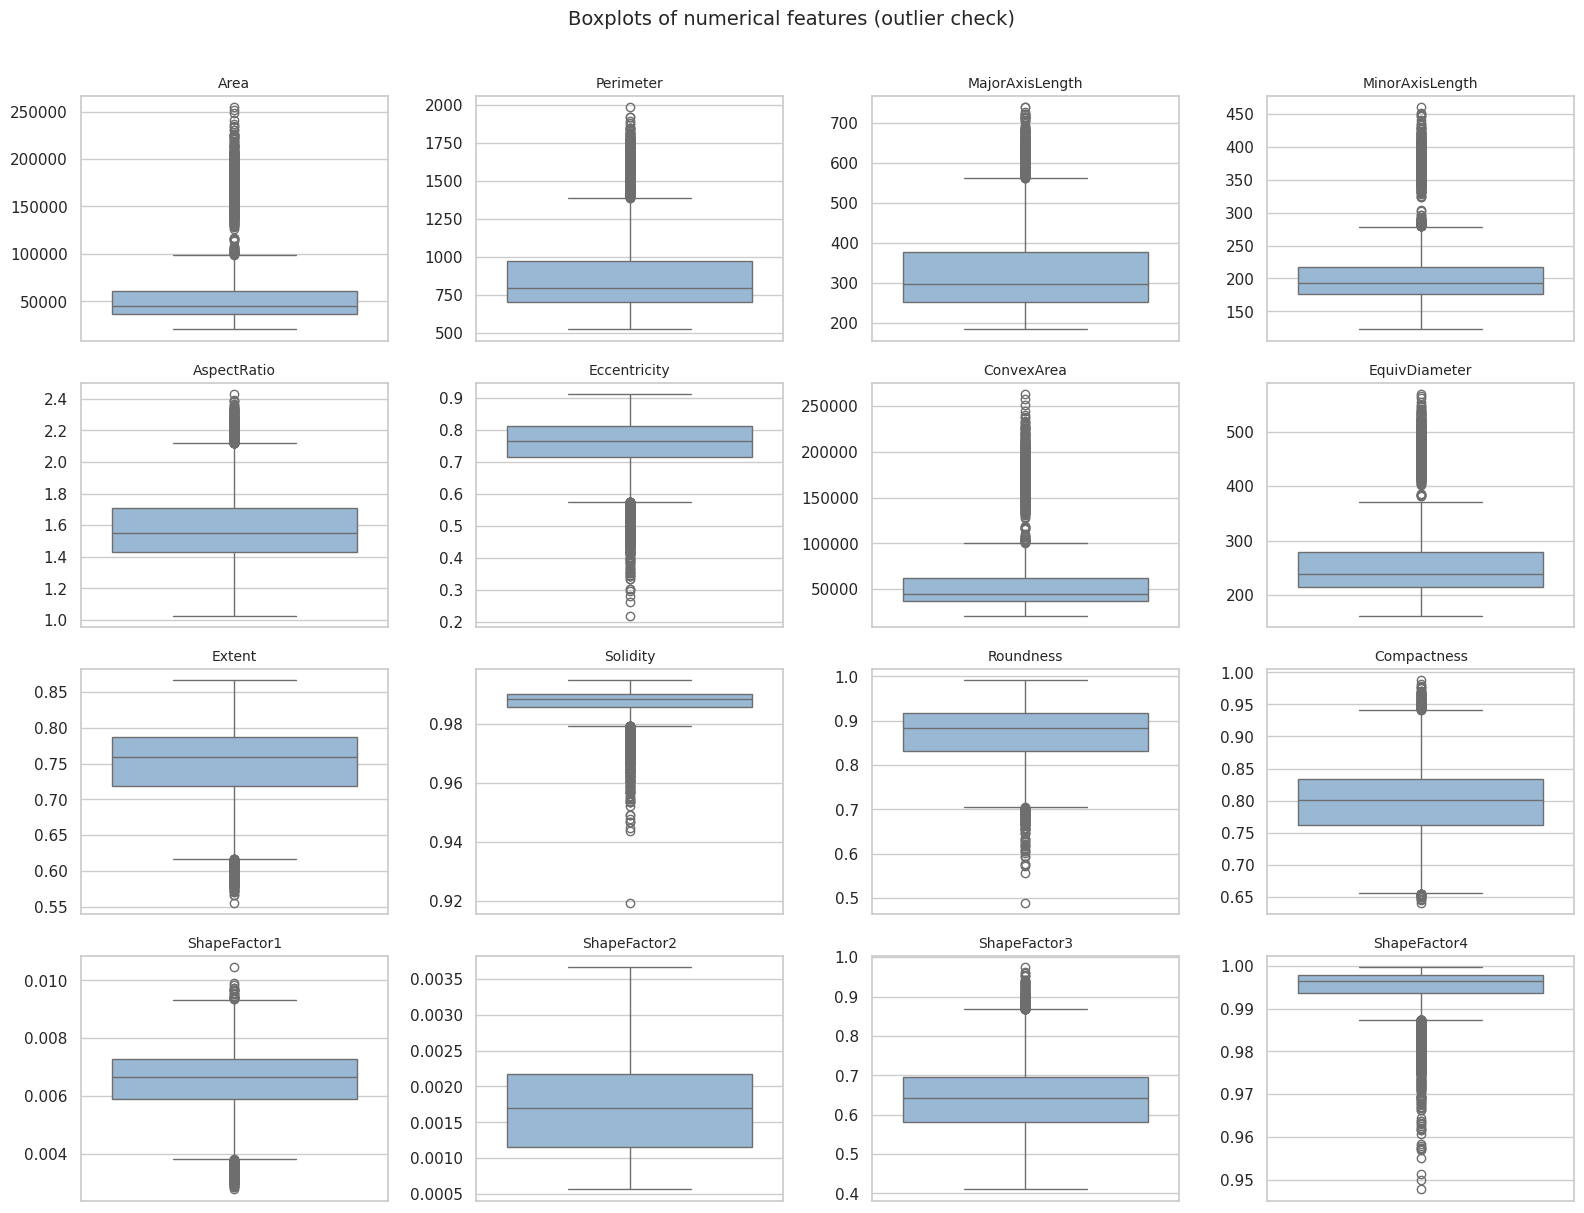

In [10]:
fig = viz.plot_boxplots(df_raw); viz.save_fig(fig, 'boxplots.png'); plt.show()

**Correlation heatmap** – many size-related features (Area, ConvexArea, EquivDiameter, Perimeter...) are almost perfectly correlated. This matters for Naive Bayes (assumes independence) and for interpreting Logistic Regression coefficients.

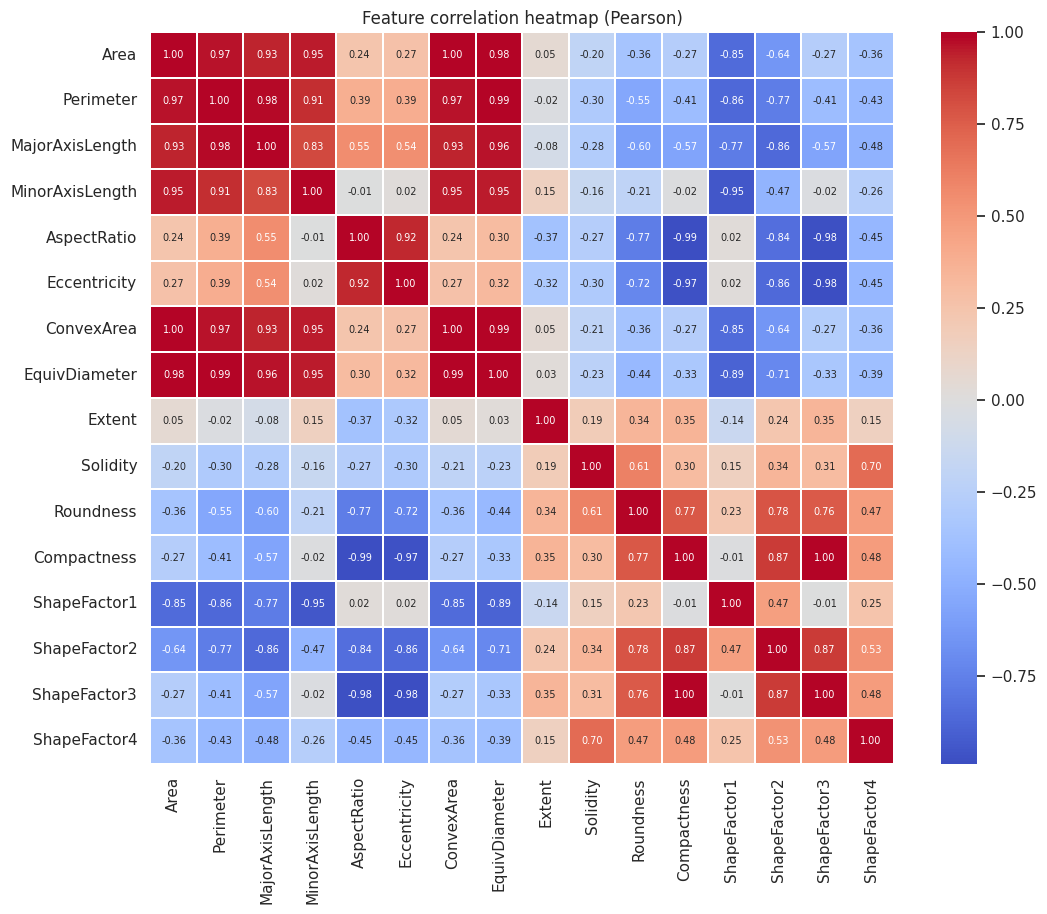

21 of 120 feature pairs have |r| > 0.9. Strongest:
Area         ConvexArea       0.9999
Compactness  ShapeFactor3     0.9987
Perimeter    EquivDiameter    0.9914
AspectRatio  Compactness      0.9877
ConvexArea   EquivDiameter    0.9852


In [11]:
fig = viz.plot_correlation_heatmap(df_raw); viz.save_fig(fig, 'correlation_heatmap.png'); plt.show()
corr = df_raw[config.FEATURE_COLS].corr().abs()
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().dropna().sort_values(ascending=False)
print(f"{(pairs > 0.9).sum()} of {len(pairs)} feature pairs have |r| > 0.9. Strongest:")
print(pairs.head(5).round(4).to_string())

**Do features separate the classes?** A few features split by class.

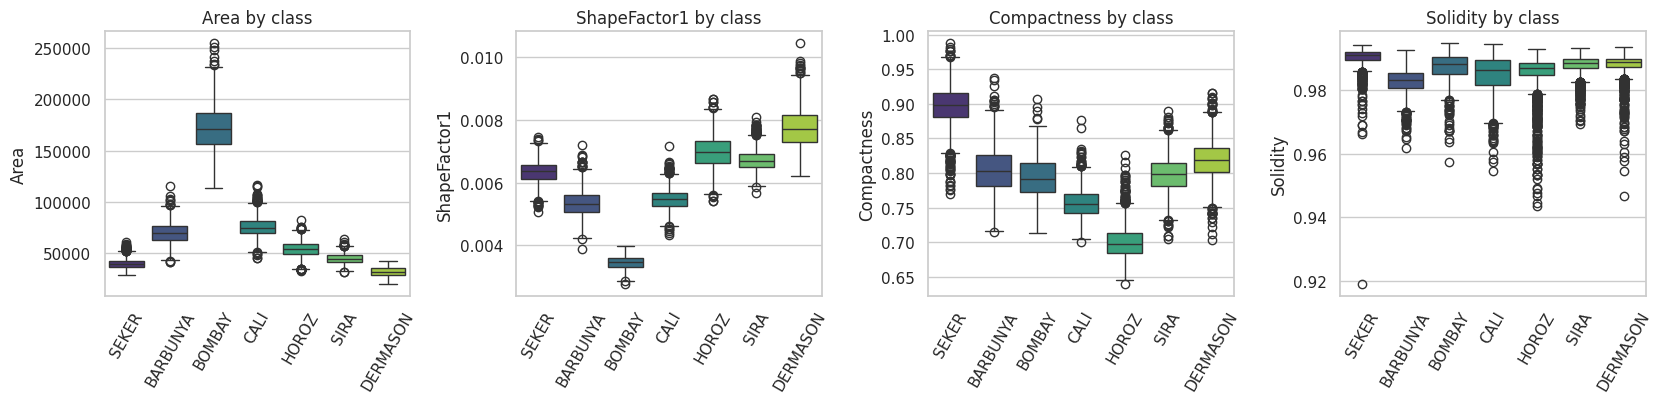

In [12]:
fig = viz.plot_features_by_class(df_raw); viz.save_fig(fig, 'features_by_class.png'); plt.show()

## Phase 3 · Data preprocessing
Steps (all in `src/preprocessing.py`):
1. Separate features `X` (16 columns) and target `y`.
2. **Missing values** – none are present; the code would drop affected rows rather than invent values.
3. **Duplicates** – exact duplicate rows are removed (first copy kept) *before* splitting so no bean can appear in both sets. The count removed is reported, never hidden.
4. **Encode target** – `LabelEncoder` maps class names to 0..6 (needed for the AUC/MCC calculations); the encoder is saved with the models.
5. **Split** – 80:20, `stratify=y`, `random_state=42`: one split, reused by all five models.
6. **Scaling** – `StandardScaler` is a step *inside each Pipeline*, so it is fitted on training data only. Fitting it on the full dataset would leak test-set mean/variance into training.

In [13]:
df, clean_log = preprocessing.clean_dataset(df_raw)
print("Cleaning log:", clean_log)
df.to_csv(config.CLEAN_CSV, index=False)

split = preprocessing.split_data(df)
X_train, X_test = split["X_train"], split["X_test"]
y_train, y_test = split["y_train"], split["y_test"]
le = split["label_encoder"]; classes = list(le.classes_); K = len(classes)
preprocessing.save_splits(split)   # writes data/processed/train.csv, test.csv and data/test_data.csv

print(f"Train: {X_train.shape}   Test: {X_test.shape}")
print("Classes (encoded 0..K-1):", dict(enumerate(classes)))
share = pd.DataFrame({"train": y_train.value_counts(normalize=True).sort_index(),
                      "test": y_test.value_counts(normalize=True).sort_index()}); share.index = classes
display(share.round(4))   # stratification check: proportions should match

Cleaning log: {'rows_before': 13611, 'missing_cells': 0, 'duplicates_removed': 68, 'rows_after': 13543}


Train: (10834, 16)   Test: (2709, 16)
Classes (encoded 0..K-1): {0: 'BARBUNYA', 1: 'BOMBAY', 2: 'CALI', 3: 'DERMASON', 4: 'HOROZ', 5: 'SEKER', 6: 'SIRA'}


,train,test
BARBUNYA,0.0976,0.0978
BOMBAY,0.0386,0.0384
CALI,0.1204,0.1203
DERMASON,0.2619,0.2617
HOROZ,0.1373,0.1373
SEKER,0.1496,0.1499
SIRA,0.1947,0.1945


**Leakage check.** The scaler inside each pipeline will be fitted on `X_train` only; below we prove the stored mean equals the *training* mean, not the full-data mean.

## Phase 4 · Model implementation
All five models are `Pipeline([StandardScaler, classifier])`. Hyperparameters were set **a priori** (sensible defaults) and were **not** tuned on the test set.

| Model | How it works | Why appropriate here | Key hyper-parameters used | Advantages | Limitations |
|---|---|---|---|---|---|
| **Logistic Regression** | Learns a linear score per class and turns them into probabilities with softmax; minimises cross-entropy. | Fast, strong baseline for numeric features once scaled. | `max_iter=2000`, default L2 `C=1` | Probabilistic, interpretable, little overfitting | Only linear class boundaries |
| **Decision Tree** | Recursively splits features to make child nodes purer (Gini). | Needs no scaling, captures non-linear rules. | `max_depth=10`, `min_samples_leaf=5` (limit overfitting) | Interpretable, handles mixed scales | Unstable, overfits easily, coarse probabilities |
| **KNN** | Predicts by (distance-weighted) vote of the k closest training points. | Classes form clusters in shape space. | `n_neighbors=7`, `weights='distance'` | No training, flexible boundaries | Needs scaling, slow prediction, sensitive to noisy/correlated features |
| **Gaussian Naive Bayes** | Bayes' rule with the assumption that features are independent and Gaussian within a class. | Features are continuous; very cheap baseline. | defaults (`var_smoothing=1e-9`) | Very fast, few parameters | Independence assumption is violated by correlated features |
| **SVM (RBF)** | Finds a maximum-margin boundary in an implicit high-dimensional space via the RBF kernel; multiclass via one-vs-one. | Smooth non-linear boundaries on scaled data. | `C=1.0`, `gamma='scale'`, `probability=True` | Strong accuracy, robust to outliers via margin | Slower on big data, needs scaling, `probability=True` adds internal cross-validation cost |

`probability=True` for SVM makes `predict_proba()` available (Platt scaling) so AUC is computed identically for all five models.

In [14]:
pipes = train_models.build_pipelines()
for name, p in pipes.items():
    print(f"{name:<20s}", " -> ".join(f"{n}:{type(s).__name__}" for n, s in p.steps))

print("\nTraining on the TRAIN split only ...")
pipes, train_secs = train_models.train_all(X_train, y_train)

# Leakage proof: scaler statistics equal the training-set statistics
sc = pipes["SVM"].named_steps["scaler"]
assert np.allclose(sc.mean_, X_train.mean().values)
assert not np.allclose(sc.mean_, df[config.FEATURE_COLS].mean().values)
print("\nLeakage check passed: scaler mean == training mean (and != full-data mean).")

Logistic Regression  scaler:StandardScaler -> clf:LogisticRegression
Decision Tree        scaler:StandardScaler -> clf:DecisionTreeClassifier
KNN                  scaler:StandardScaler -> clf:KNeighborsClassifier
Naive Bayes          scaler:StandardScaler -> clf:GaussianNB
SVM                  scaler:StandardScaler -> clf:SVC

Training on the TRAIN split only ...


  trained Logistic Regression  in   0.19s


  trained Decision Tree        in   0.18s
  trained KNN                  in   0.01s
  trained Naive Bayes          in   0.01s


  trained SVM                  in   2.72s

Leakage check passed: scaler mean == training mean (and != full-data mean).


## Phase 5 · Evaluation metrics
For this 7-class problem:
- **Accuracy** – share of correct predictions.
- **AUC** – multiclass ROC-AUC, **one-vs-rest, macro-averaged**, computed from `predict_proba()`.
- **Precision / Recall / F1** – **macro-averaged** (each class counts equally, which matters because Bombay is only ~4 % of the data).
- **MCC** – Matthews correlation coefficient (multiclass version), a single balanced score that is robust to imbalance.

`zero_division=0` is used so a class that is never predicted gives 0 rather than an error. Our `safe_macro_auc` equals sklearn's `roc_auc_score(multi_class='ovr', average='macro')` when every class is present (asserted below) and only differs by skipping classes that are absent from an uploaded test file.

In [15]:
from sklearn.metrics import roc_auc_score
results, store = ev.evaluate_all(pipes, X_test, y_test, K)
for name in pipes:   # AUC cross-check against sklearn's built-in
    ref = roc_auc_score(y_test, store[name]["proba"], multi_class="ovr", average="macro")
    assert abs(ref - results.set_index("ML Model Name").loc[name, "AUC"]) < 1e-12
results_rounded = results.round(4)
results_rounded.to_csv(config.COMPARISON_CSV, index=False)
display(results_rounded)

,ML Model Name,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9192,0.9947,0.9307,0.9300,0.9302,0.9023
1,Decision Tree,0.9070,0.9779,0.9220,0.9204,0.9211,0.8875
2,KNN,0.9136,0.9854,0.9268,0.9237,0.9250,0.8956
3,Naive Bayes,0.8970,0.9911,0.9081,0.9082,0.9072,0.8762
4,SVM,0.9210,0.9945,0.9342,0.9317,0.9328,0.9045


### Confusion matrix and classification report for every model

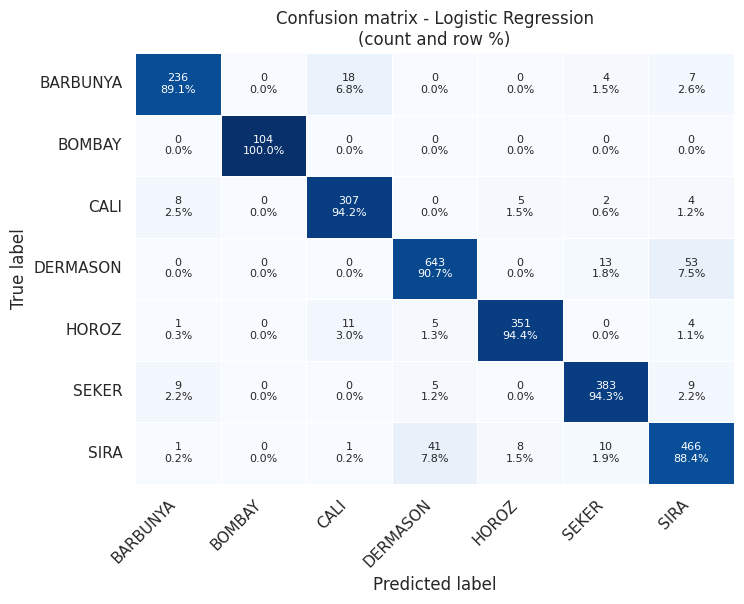

Classification report - Logistic Regression
              precision    recall  f1-score   support

    BARBUNYA     0.9255    0.8906    0.9077       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9110    0.9417    0.9261       326
    DERMASON     0.9265    0.9069    0.9166       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9296    0.9433    0.9364       406
        SIRA     0.8582    0.8843    0.8710       527

    accuracy                         0.9192      2709
   macro avg     0.9307    0.9300    0.9302      2709
weighted avg     0.9197    0.9192    0.9193      2709



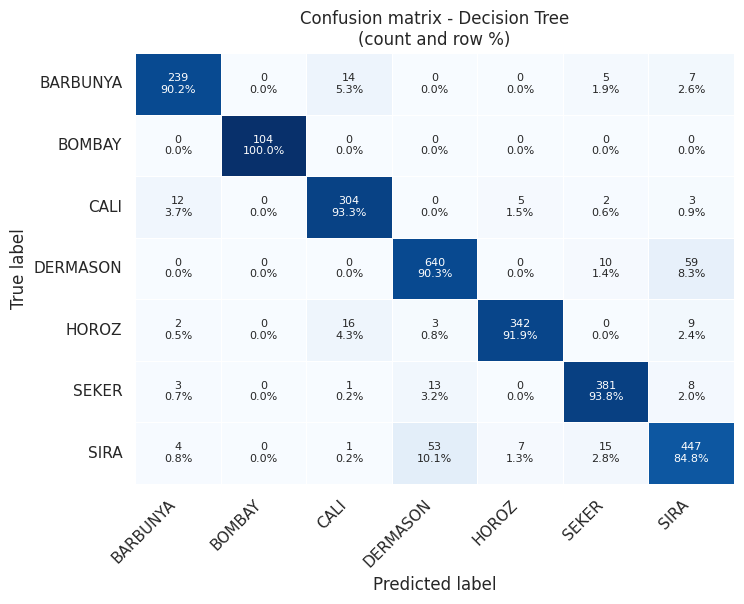

Classification report - Decision Tree
              precision    recall  f1-score   support

    BARBUNYA     0.9192    0.9019    0.9105       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9048    0.9325    0.9184       326
    DERMASON     0.9027    0.9027    0.9027       709
       HOROZ     0.9661    0.9194    0.9421       372
       SEKER     0.9225    0.9384    0.9304       406
        SIRA     0.8386    0.8482    0.8434       527

    accuracy                         0.9070      2709
   macro avg     0.9220    0.9204    0.9211      2709
weighted avg     0.9075    0.9070    0.9071      2709



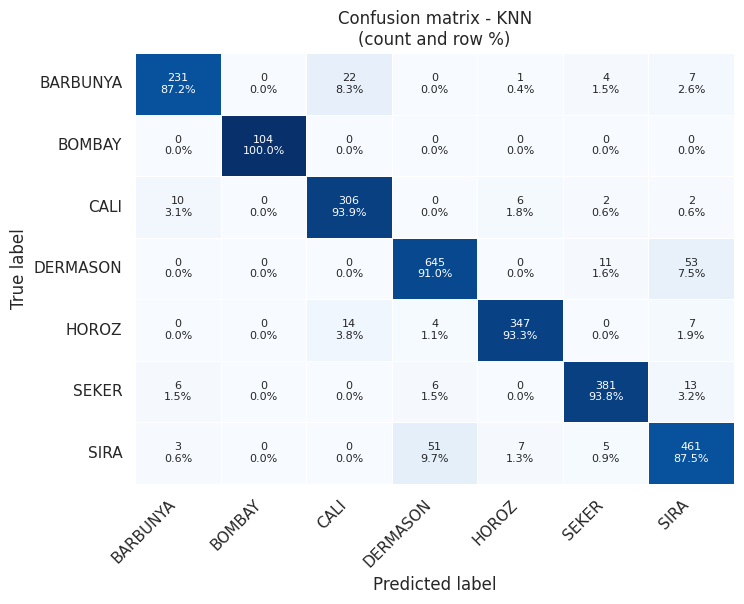

Classification report - KNN
              precision    recall  f1-score   support

    BARBUNYA     0.9240    0.8717    0.8971       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8947    0.9387    0.9162       326
    DERMASON     0.9136    0.9097    0.9117       709
       HOROZ     0.9612    0.9328    0.9468       372
       SEKER     0.9454    0.9384    0.9419       406
        SIRA     0.8490    0.8748    0.8617       527

    accuracy                         0.9136      2709
   macro avg     0.9268    0.9237    0.9250      2709
weighted avg     0.9144    0.9136    0.9138      2709



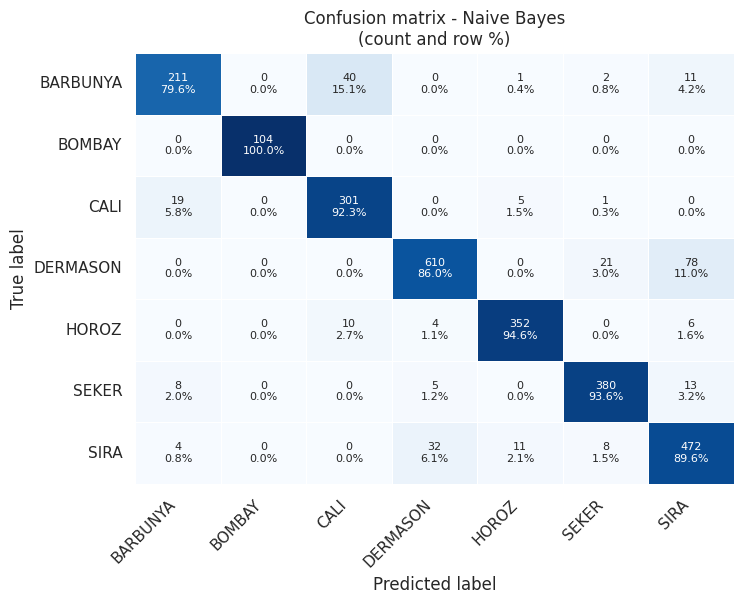

Classification report - Naive Bayes
              precision    recall  f1-score   support

    BARBUNYA     0.8719    0.7962    0.8323       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.8575    0.9233    0.8892       326
    DERMASON     0.9370    0.8604    0.8971       709
       HOROZ     0.9539    0.9462    0.9501       372
       SEKER     0.9223    0.9360    0.9291       406
        SIRA     0.8138    0.8956    0.8528       527

    accuracy                         0.8970      2709
   macro avg     0.9081    0.9082    0.9072      2709
weighted avg     0.8997    0.8970    0.8972      2709



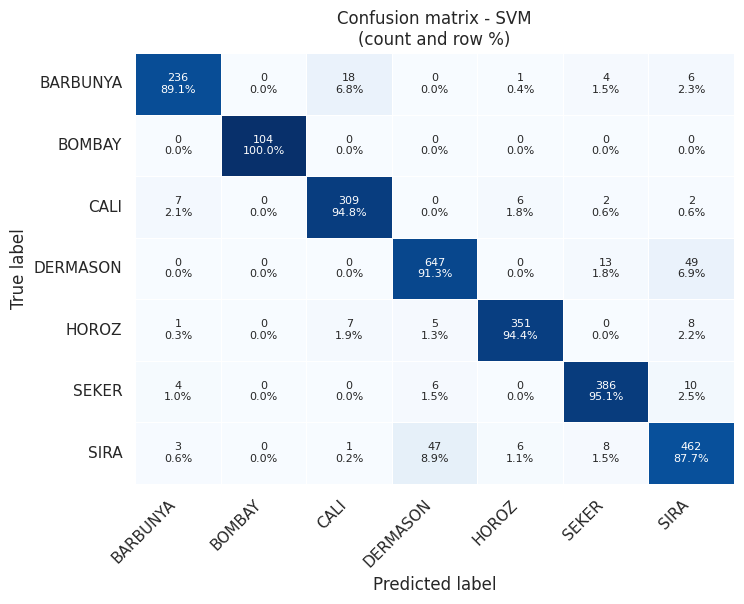

Classification report - SVM
              precision    recall  f1-score   support

    BARBUNYA     0.9402    0.8906    0.9147       265
      BOMBAY     1.0000    1.0000    1.0000       104
        CALI     0.9224    0.9479    0.9349       326
    DERMASON     0.9177    0.9126    0.9151       709
       HOROZ     0.9643    0.9435    0.9538       372
       SEKER     0.9346    0.9507    0.9426       406
        SIRA     0.8603    0.8767    0.8684       527

    accuracy                         0.9210      2709
   macro avg     0.9342    0.9317    0.9328      2709
weighted avg     0.9214    0.9210    0.9211      2709



In [16]:
from sklearn.metrics import confusion_matrix, classification_report
for name in pipes:
    slug = config.MODEL_FILES[name].replace(".joblib", "")
    pred = store[name]["pred"]
    cm = confusion_matrix(y_test, pred)
    fig = viz.plot_confusion_matrix(cm, classes, f"Confusion matrix - {name}")
    viz.save_fig(fig, f"confusion_matrix_{slug}.png"); plt.show()
    print(f"Classification report - {name}")
    print(classification_report(y_test, pred, target_names=classes, digits=4, zero_division=0))

## Phase 6 · Model comparison

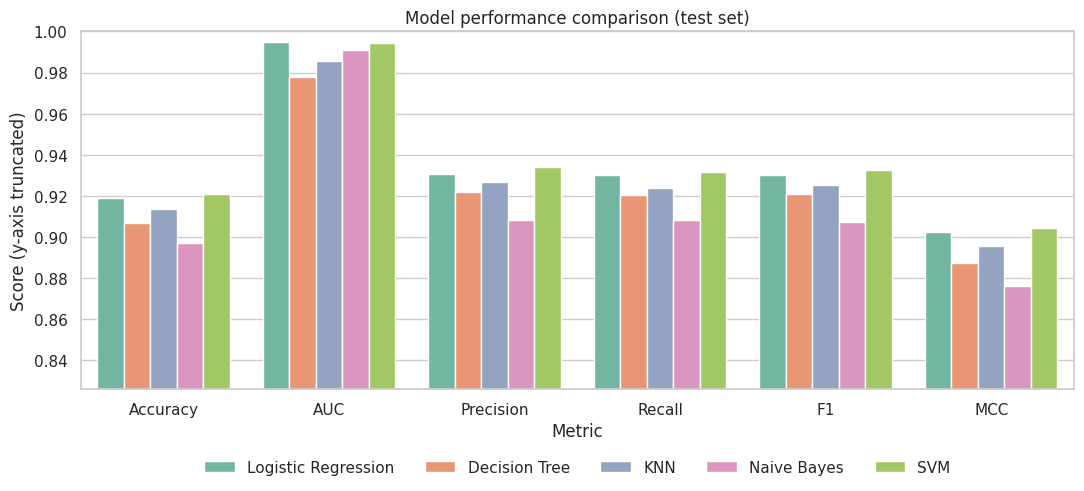

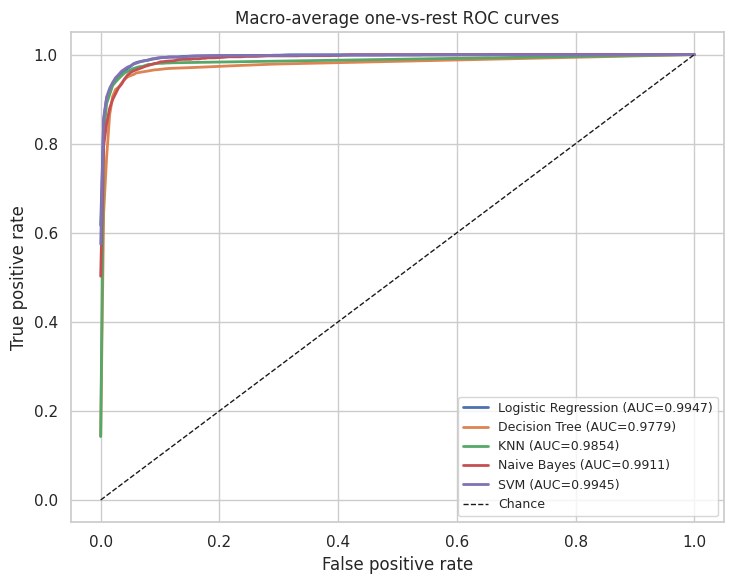

Best model per metric:
Accuracy                     SVM
AUC          Logistic Regression
Precision                    SVM
Recall                       SVM
F1                           SVM
MCC                          SVM


In [17]:
fig = viz.plot_model_comparison(results); viz.save_fig(fig, "model_comparison.png"); plt.show()
curves = {}
for name in pipes:
    fpr, tpr = viz.macro_roc_curve(y_test, store[name]["proba"], K)
    curves[name] = (fpr, tpr, results.set_index("ML Model Name").loc[name, "AUC"])
fig = viz.plot_roc_comparison(curves); viz.save_fig(fig, "roc_comparison.png"); plt.show()
best = results.set_index("ML Model Name")[ev.METRIC_COLS].idxmax()
print("Best model per metric:"); print(best.to_string())

### Generalisation diagnostics (training data only; the test set is not used for CV)
Training accuracy vs 5-fold cross-validated accuracy vs test accuracy shows which models over-fit.

In [18]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score
skf = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)
rows = []
for name, p in pipes.items():
    cvp = clone(p)
    if name == "SVM": cvp.set_params(clf__probability=False)   # accuracy does not need Platt scaling; saves time
    cv = cross_val_score(cvp, X_train, y_train, cv=skf, scoring="accuracy")
    tr = accuracy_score(y_train, p.predict(X_train)); te = accuracy_score(y_test, store[name]["pred"])
    rows.append({"ML Model Name": name, "Train Accuracy": tr, "CV Accuracy (5-fold, train only)": cv.mean(),
                 "CV Std": cv.std(), "Test Accuracy": te, "Train-Test Gap": tr - te})
details = pd.DataFrame(rows).round(4); details.to_csv(config.DETAILS_CSV, index=False); display(details)

,ML Model Name,Train Accuracy,"CV Accuracy (5-fold, train only)",CV Std,Test Accuracy,Train-Test Gap
0,Logistic Regression,0.9260,0.9243,0.0030,0.9192,0.0068
1,Decision Tree,0.9518,0.9112,0.0059,0.9070,0.0448
2,KNN,1.0000,0.9240,0.0055,0.9136,0.0864
3,Naive Bayes,0.8972,0.8968,0.0060,0.8970,0.0002
4,SVM,0.9342,0.9300,0.0057,0.9210,0.0132


### Model performance observations (computed from the saved results)

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9192 | 0.9947 | 0.9307 | 0.9300 | 0.9302 | 0.9023 |
| Decision Tree | 0.9070 | 0.9779 | 0.9220 | 0.9204 | 0.9211 | 0.8875 |
| KNN | 0.9136 | 0.9854 | 0.9268 | 0.9237 | 0.9250 | 0.8956 |
| Naive Bayes | 0.8970 | 0.9911 | 0.9081 | 0.9082 | 0.9072 | 0.8762 |
| SVM | 0.9210 | 0.9945 | 0.9342 | 0.9317 | 0.9328 | 0.9045 |

| ML Model Name | Observation About Model Performance |
|---|---|
| Logistic Regression | Second-best on Accuracy (0.9192), Precision, Recall, F1 and MCC, and the highest AUC (0.9947), only 0.0002 above SVM. Train-test accuracy gap is just 0.0068, so it generalises very well. A linear decision surface on standardised features is almost as good as the non-linear SVM here. |
| Decision Tree | Accuracy 0.9070 and the lowest AUC of all models (0.9779): a tree outputs piecewise-constant leaf probabilities, so its class ranking is coarser. It shows the largest genuine overfitting among the models (train 0.9518 vs test 0.9070, gap 0.0448) even with max_depth=10 and min_samples_leaf=5. |
| KNN | Mid-table: Accuracy 0.9136, F1 0.9250, AUC 0.9854. Its training accuracy is 1.0000 only because distance weighting makes every training point its own nearest neighbour, so the 0.0864 train-test gap is partly an artefact; the 5-fold CV accuracy on the training data (0.9240) is the fairer indicator. Prediction is also the slowest at inference time because it stores the whole training set. |
| Naive Bayes | Weakest on Accuracy (0.8970), F1 (0.9072) and MCC (0.8762), yet third-highest on AUC (0.9911): it ranks classes reasonably but its hard decisions are worse. The independence assumption is clearly violated - 21 of 120 feature pairs have an absolute correlation above 0.9 - which is a likely reason. Gap 0.0002 means no overfitting; the limitation is bias, not variance. |
| SVM | Best on Accuracy (0.9210), Precision (0.9342), Recall (0.9317), F1 (0.9328) and MCC (0.9045); AUC (0.9945) is second, 0.0002 behind Logistic Regression. It also has the best 5-fold CV accuracy on the training data (0.9300) and a modest gap of 0.0132. |

**Which model performs best?** SVM (top on Accuracy, Precision, Recall, F1, MCC).  
**Highest AUC:** Logistic Regression (SVM is only 0.0002 behind).  
**Best precision/recall balance:** SVM (highest F1 = 0.9328; Precision 0.9342 and Recall 0.9317 are both the highest, differing by 0.0025).  
**Generalisation:** Naive Bayes has the smallest gap (0.0002) but at lower accuracy; among the strong models Logistic Regression (0.0068) and SVM (0.0132) generalise best.  
**Poor performers:** Naive Bayes (lowest Accuracy/F1/MCC); Decision Tree has the lowest AUC and the biggest real overfitting gap.  
Per-class (SVM): the hardest class is SIRA (F1 0.8684); BOMBAY is the easiest (F1 1.0000). The most frequent mix-up is DERMASON vs SIRA (96 test beans misassigned between them).

**Overall winner: Support Vector Machine (RBF).** It ranks first on five of the six metrics (Accuracy, Precision, Recall, F1, MCC) and second on AUC (only 0.0002 behind Logistic Regression), and has the best cross-validated accuracy on the training data. Caveat: its accuracy lead over Logistic Regression is 0.0018, smaller than one standard error of the test accuracy (about 0.0052 for n=2709), so SVM and Logistic Regression should be regarded as statistically very close; Logistic Regression is the simpler, faster alternative.

*These statements are generated from `reports/model_comparison.csv` and `reports/model_comparison_details.csv` by `tools/observations.py`, which asserts every claim against the numbers.*

## Phase 7 · Saving the trained pipelines and metadata

In [19]:
train_models.save_all(pipes, split, clean_log, train_secs)
for f in sorted(config.MODELS_DIR.iterdir()): print(f"{f.name:<28s}{f.stat().st_size/1024:>9.1f} KB")

# Reload test: a saved pipeline must reproduce the in-memory predictions exactly
for name, fname in config.MODEL_FILES.items():
    reloaded = joblib.load(config.MODELS_DIR / fname)
    assert (reloaded.predict(X_test) == store[name]["pred"]).all()
print("\nAll five saved pipelines reload and reproduce identical predictions.")
loaded_svm = joblib.load(config.MODELS_DIR / "svm.joblib")          # load WITHOUT retraining
print("Loaded SVM predicts the first 5 test beans as:", le.inverse_transform(loaded_svm.predict(X_test.head(5))))
print("True labels of those 5 beans              :", list(le.inverse_transform(y_test.head(5))))
print("Held-out test file for the Streamlit app:", config.SAMPLE_TEST_CSV.relative_to(ROOT))

decision_tree.joblib             58.2 KB
knn.joblib                     1441.0 KB
label_encoder.joblib              0.5 KB
logistic_regression.joblib        3.1 KB
metadata.json                     0.9 KB
naive_bayes.joblib                3.9 KB
svm.joblib                      519.0 KB



All five saved pipelines reload and reproduce identical predictions.
Loaded SVM predicts the first 5 test beans as: ['SEKER' 'DERMASON' 'DERMASON' 'HOROZ' 'SEKER']
True labels of those 5 beans              : ['SEKER', 'DERMASON', 'DERMASON', 'HOROZ', 'SEKER']
Held-out test file for the Streamlit app: data/test_data.csv


## Conclusion
All five models were trained on the same stratified 80:20 split of the cleaned Dry Bean data and scored with the same six metrics.
See the observations above for the winner and the caveats. Next steps: run `python -m src.evaluate_models` to regenerate every report/figure from the CLI, launch `streamlit run app.py`, and follow `deployment/` for GitHub and Streamlit Community Cloud.

### Common errors and fixes
| Symptom | Cause | Fix |
|---|---|---|
| `ConnectionError: Error connecting to server` in Option A | No internet / UCI blocked | Use Option B with the downloaded file |
| `FileNotFoundError ... Dry_Bean_Dataset.xlsx` | File not in `data/raw/` | Download from Kaggle/UCI and place it there |
| `ModuleNotFoundError: src` | Notebook started from another folder | Run Jupyter from the project root or `notebooks/` |
| `ValueError: Schema mismatch` | Different/extra columns in your file | Check the printed lists; target must be named via `TARGET_COLUMN` |
| `InconsistentVersionWarning` when loading `.joblib` | scikit-learn version differs from 1.8.0 | `pip install -r requirements.txt` or retrain with `python -m src.train_models` |